# Lab Report: Interpolation
## Algorithm to implement the lagrange interpolation

In [ ]:
from google.colab import files


### Choose a cambered airfoil NACA-abcd. For given number of points on the airfoil geometry (N), reconstruct smooth airfoil surface.
### ▶ Use random number generator in numpy to choose each the maximum camber, the location of maximum camber and the the percentage of thickness to chord.
### ▶ Use the function ’Lagrng()’ that you wrote to reconstruct the airfoil.
### ▶ Plot the original airfoil and the reconstructed one.
### ▶ Quantify the error (max, RMS) between the true and reconstructed results.
### ▶ Document your work on ’how can you improve your results by choosing spacing between data points?’
### ▶ Reconstruct the airfoil using cubic splines and quantify the errors. This requires writing a python function for cubic spline interpolation


**Lagrange Interpolation**

Given N data points, Lagrange interpolation constructs a single polynomial 
of degree N-1 that passes through all of them:
$$
P(x)=\sum_{i=0}^n y(i)Li(x)
$$
$$
Li(x)=\prod_{j=0}^n \frac{(xx-xj)}{(xi-xj)}
$$


**Overall approach:**
- A NACA 4-digit airfoil is generated with randomly chosen camber (m), 
  camber location (p), and thickness (t), using `numpy.random.uniform`.
- A dense set of 500 points is generated as the "true" reference airfoil.
- A sparse set of N points (N=12) is sampled from the same 
  airfoil.
- Both Lagrange interpolation and cubic spline interpolation are used to 
  reconstruct the full airfoil shape from only the sparse points.
- The reconstructed curves are compared against the dense "true" curve, 
  and error is quantified using maximum absolute error and RMS error.


### First writing code for sum of numbers as an example

In [60]:
import numpy as np
def lagrng(x, y):
    sum=0
    for i in range(0,6):
        sum=sum+x[i]
    print(sum)

x=np.array([0,1,2,3,4,5])
y=x
lagrng(x,y)

15


### Now writing code for finding the number(coordinate) between the given cordinates

In [161]:
## Example
import numpy as np
def lagrng(x,y,n,xx):
    sum=0
    for i in range (0,n):
        product=y[i]
        for j in range(0,n):
            if i!=j:
                product=product*((xx - x[j])/(x[i] - x[j]))
        sum=sum+product
    return sum

x=np.array([0,1,2,3,4,5])
y=np.array([1,3,5,7,9,11])
lagrng(x,y,5,2.5)

np.float64(6.0)

### Now writing the same code for sin(x)

In [107]:
import numpy as np
def lagrng(x,y,n,xx):
    sum=0
    for i in range (0,n):
        product=y[i]
        for j in range(0,n):
            if i!=j:
                product=product*((xx - x[j])/(x[i] - x[j]))
        sum=sum+product
    return sum

x=np.array([0,np.pi/6, np.pi/4, np.pi/3, np.pi/2, np.pi])
y=np.sin(x)
lagrng(x,y,len(x),np.pi)

np.float64(1.2246467991473532e-16)

### Comparing the algorithm with the lagrange function
#### now here for same value of x=pi/6 both gives the same value of 0.4999... upto 14 decimal places

In [108]:
result1=lagrng(x, y, len(x), np.pi/6)
print(result1)
poly = lagrange(x, y)
result2=poly(np.pi/6)
print(result2)

0.49999999999999994
0.4999999999999987


C:\Users\patil\AppData\Local\Temp\ipykernel_14268\3736986862.py:3: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly = lagrange(x, y)


#### Now trying to create a random value selection for (m= maximum camber), (p= camber location) and (t= maximum thickness)

In [98]:
m=np.random.uniform(0.01, 0.06)               ## realistic range of maximum camber for cambered airfoil
print("maximum camber(m):", m)

p=np.random.uniform(0.15, 0.60)               ## realistic range of camber location for cambered airfoil
print("camber location(p):", p)

t=np.random.uniform(0.06, 0.18)               ## realistic range of maximum thickness for cambered airfoil
print("maximum thickness(t):", t)

maximum camber(m): 0.0585873991814921
camber location(p): 0.41484365862625106
maximum thickness(t): 0.14395361930639164


# Now defing the NACA 4 digit Airfoil for point generation

In [99]:
import matplotlib.pyplot as plt
def naca_4digit(m,p,t,n=200, x=None):
    if x is None:
        x=np.linspace(0,1,n)

    yt= 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)  #thickness distribution
    yc=np.where( x<p, 
             m/p**2 * (2*p*x - x**2),
             m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2))
    yu=yc + yt
    yl=yc - yt
    return x,yu,yl,yc

In [128]:
xtrue, yutrue, yltrue, yctrue = naca_4digit(m, p, t, n=500)          ## for actual true curve
x, yu, yl, yc= naca_4digit(m, p, t, n=12)                            ## for sparse points on curve

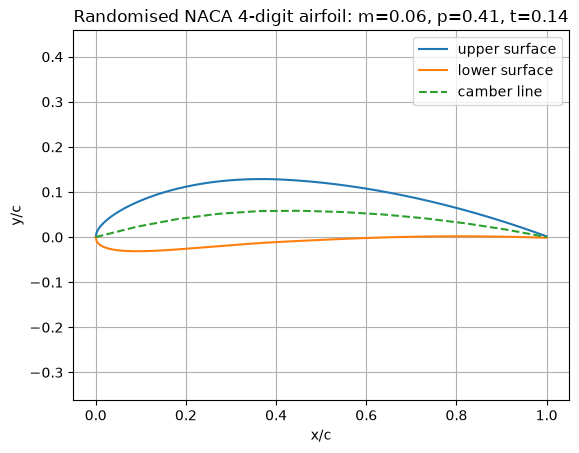

In [129]:
plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

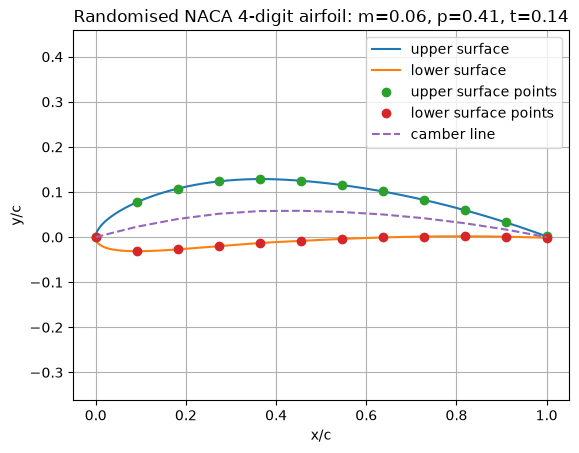

In [130]:
plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yu, 'o', label="upper surface points")
plt.plot(x,yl, 'o', label="lower surface points")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

## Example

In [131]:
numbers=[1,2,3,4,5]
squares=[]

for n in numbers :
    result = n**2
    squares.append(result)
print(squares)

[1, 4, 9, 16, 25]


## Now storing the output

In [132]:
y_new_upper = []
for xx in xtrue:                                      ## xx takes each value from xtrue
    result=(lagrng(x, yu, len(x), xx))                ## compute 1 new y value at this xx
    y_new_upper.append(result)                        ## store that y value in the list

y_new_lower = []
for xx in xtrue:                                      ## xx takes each value from xtrue
    result=(lagrng(x, yl, len(x), xx))                ## compute 1 new y value at this xx
    y_new_lower.append(result)                        ## store that y value in the list

In [133]:
print(y_new_upper [0])
print(y_new_lower [0])
print(yutrue [0])

0.0
0.0
0.0


In [134]:
mid = len(xtrue) // 2                 ## checking the value of y_new_upper nad yutrue and the midpoint
print(y_new_upper[mid])
print(yutrue[mid])
print(y_new_lower[mid])
print(yltrue[mid])

0.12073729589862157
0.12074909746774856
-0.006131544966597243
-0.006114599542989686


# Now generating all 3 graphs in one, that is with actual curve,  the sparse points and the new generated points 

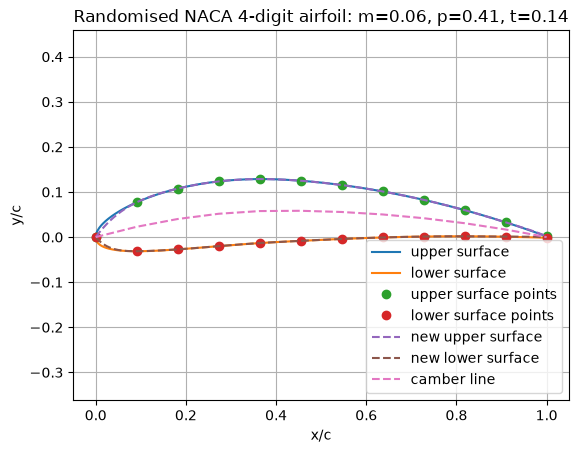

In [135]:
plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yu, 'o', label="upper surface points")
plt.plot(x,yl, 'o', label="lower surface points")
plt.plot(xtrue,y_new_upper, '--', label="new upper surface")
plt.plot(xtrue,y_new_lower, '--', label="new lower surface")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

# Now calculating error
#### Now as we have y_new_upper and y_new_lower in the list and yutrur , yltrue in the numpy.ndarray format, we cant directly subtract it to find the error


In [136]:
type(yutrue)

numpy.ndarray

In [137]:
type(y_new_upper)

list

In [138]:
y_new_upper=np.array(y_new_upper)           ## converting list into numpy array
y_new_lower=np.array(y_new_lower)

In [139]:
error_upper = yutrue - y_new_upper
          
error_lower = yltrue - y_new_lower


max_error_upper=np.max(abs(error_upper))         ## getting the absolute value as there can be both positive and negative value of error
print(f"max_error_upper={max_error_upper}")

max_error_lower=np.max(abs(error_lower))
print(f"max_error_lower={max_error_lower}")

max_error_upper=0.010430829453602023
max_error_lower=0.007784315320860434


### now to calculate error using RMS
$$
RMS=\sqrt \frac{1}{n} \sum_{i=1}^n error_i^2
$$

In [140]:
rms_error_upper=np.sqrt(np.mean(error_upper**2))
print(f"RMS_error_upper={rms_error_upper}")
rms_error_lower=np.sqrt(np.mean(error_lower**2))
print(f"RMS_error_lower={rms_error_lower}")

RMS_error_upper=0.0018538033308966688
RMS_error_lower=0.0011128039818353239


# How can you improve your results by choosing spacing between data points?
### As in this report we have selected n=12 , so there are 12 sparse points evenly spread out over the upper curve as well as lower curve.
### But the curve is too steep near the leading edge and flat near the trailing edge, so it does not take this into consideration.

#### Thatswhy using cosine spaceing to generate more points near leading edge so it can capture the steepness of the airfoil.

In [141]:
theta = np.linspace(0, np.pi, 12)
x_cos = (1 - np.cos(theta)) / 2

x_cos, yu_cos, yl_cos, yc_cos = naca_4digit(m, p, t, x=x_cos)
print(x_cos)

[0.         0.02025351 0.07937323 0.17256963 0.29229249 0.42884258
 0.57115742 0.70770751 0.82743037 0.92062677 0.97974649 1.        ]


### So here as we can see the points have small gaps near the leading edge , large gap in middle and again small gaps near trailing edge.

In [142]:
## now creating new lagrange for the cos spacing
y_new_upper_cos = []
for xx in xtrue:                                  
    result=(lagrng(x_cos, yu_cos, len(x_cos), xx))                
    y_new_upper_cos.append(result)   
y_new_upper_cos=np.array(y_new_upper_cos)

y_new_lower_cos = []
for xx in xtrue:                                    
    result=(lagrng(x_cos, yl_cos, len(x_cos), xx))                
    y_new_lower_cos.append(result)                        
y_new_lower_cos=np.array(y_new_lower_cos)

In [143]:
## now calculating error using cosine spacing
error_upper_cos= yutrue - y_new_upper_cos
error_lower_cos= yltrue - y_new_lower_cos

max_error_upper_cos=np.max(np.abs(error_upper_cos))
max_error_lower_cos=np.max(np.abs(error_lower_cos))

rms_error_upper_cos=np.sqrt(np.mean(error_upper_cos**2))
rms_error_lower_cos=np.sqrt(np.mean(error_lower_cos**2))

print(f"Max_error_upper_cos={max_error_upper_cos}")
print(f"Max_error_lower_cos={max_error_lower_cos}")
print(f"RMS_error_upper_cos={rms_error_upper_cos}")
print(f"RMS_error_lower_cos={rms_error_lower_cos}")

Max_error_upper_cos=0.005745039186313673
Max_error_lower_cos=0.005738261979194217
RMS_error_upper_cos=0.0009503981053731953
RMS_error_lower_cos=0.0009043542006386653


### Reconstructing the same n=12 points with cosine spacing reduced the maximum error on the lower surface error also improved slightly.
### So by this we can say that the location of interpolation points matter, which can significantly affect the accuracy of the curve, particularly in the region of high curvature such as leading edge.

### References
1. NACA airfoil equations: https://en.wikipedia.org/wiki/NACA_airfoil
2. Lagrange polynomial: https://en.wikipedia.org/wiki/Lagrange_polynomial
